# Retargeted thermal spectral QSP

The fixed-local-coupling chain is $H_n=.6\sum ZZ+.35\sum X$, with $\hbar=k_B=E_0=1$. For each $n,\beta$, this notebook generates new parity phases for $a=\beta\alpha/2$. The accepted map is $e^{-\beta(H+\alpha I)/2}/4$. Bell preparation and unconditioned reference discard give a Gibbs approximation. Classical matrices below are references, never gates.

Coefficient/PREPARE-weight/parameter certificates apply to the declared logical circuit, with exact named Cliffords/controls and stored binary64 angles. SDK nested-control realization and flat compilation checks are numerical; synthesis and physical/instrument certificates remain separate. No quantum shots or Lean proof are supplied.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
from qiskit.quantum_info import Operator
root=Path.cwd()
local_module=(root/"thermal_spectral.py").is_file()
if not local_module and root.name=="notebooks" and (root.parent/"src/openquantum/simulation/thermal_spectral.py").is_file():
    root=root.parent
if not local_module and (root/"src/openquantum/simulation/thermal_spectral.py").is_file():
    sys.path.insert(0,str(root/"src"))
    from openquantum.simulation import thermal_spectral as ts
    from openquantum.simulation.qsp_phase_generation import real_qsp_response
    asset_dir=root/"assets/generated/simulation/thermal-spectral"
else:
    sys.path.insert(0,str(root))
    import thermal_spectral as ts
    from qsp_phase_generation import real_qsp_response
    asset_dir=root
get_ipython().run_line_magic("matplotlib","inline")
terms=ts.spin_chain_terms(2)
core=ts.build_thermal_spectral_filter(terms,beta=1.5,filter_error=1e-6,gibbs_error=1e-4)
check=ts.thermal_spectral_check(core)
contract=core.metadata["error_contract"]
assert check["gibbs_trace_distance"] < 1e-4
assert contract["implemented_loading_rounding_certified"]
print(f"Selected n=2 beta=1.5: {core.num_qubits} logical wires, degrees {core.metadata['even_degree']}/{core.metadata['odd_degree']}")


Selected n=2 beta=1.5: 8 logical wires, degrees 6/7


## Literal small circuit

The displayed one-spin $H=.35X$ circuit is a small access/selector demo at $\beta=.75$. The selected two-spin analysis below is noncommuting. Neither circuit uses a dense exponential or a Pauli-power table. The source contains every Bell, PREPARE, SELECT, inverse and conditional phase gate.

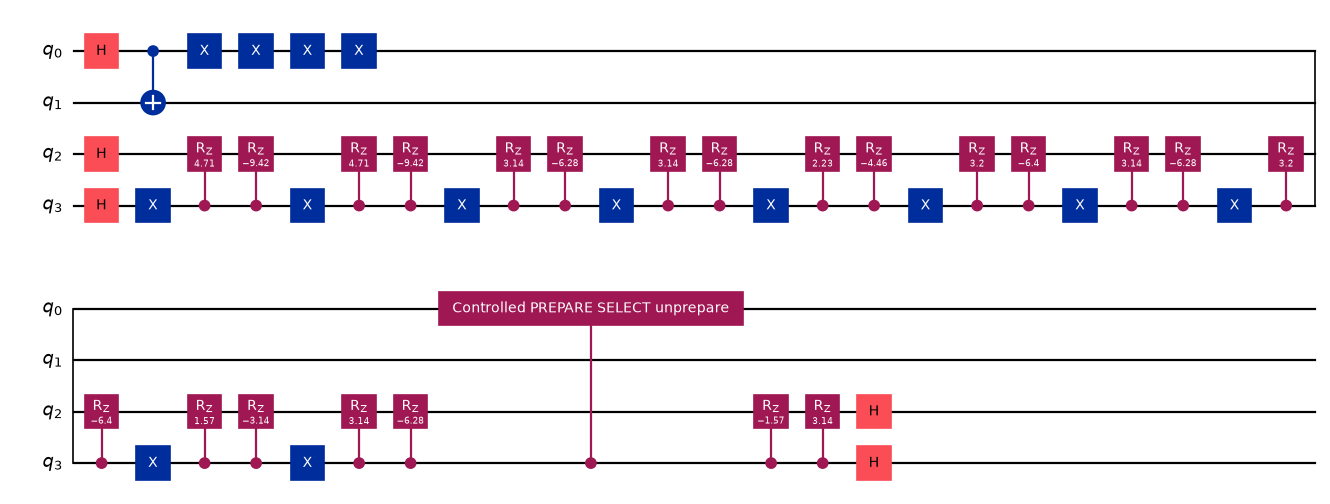

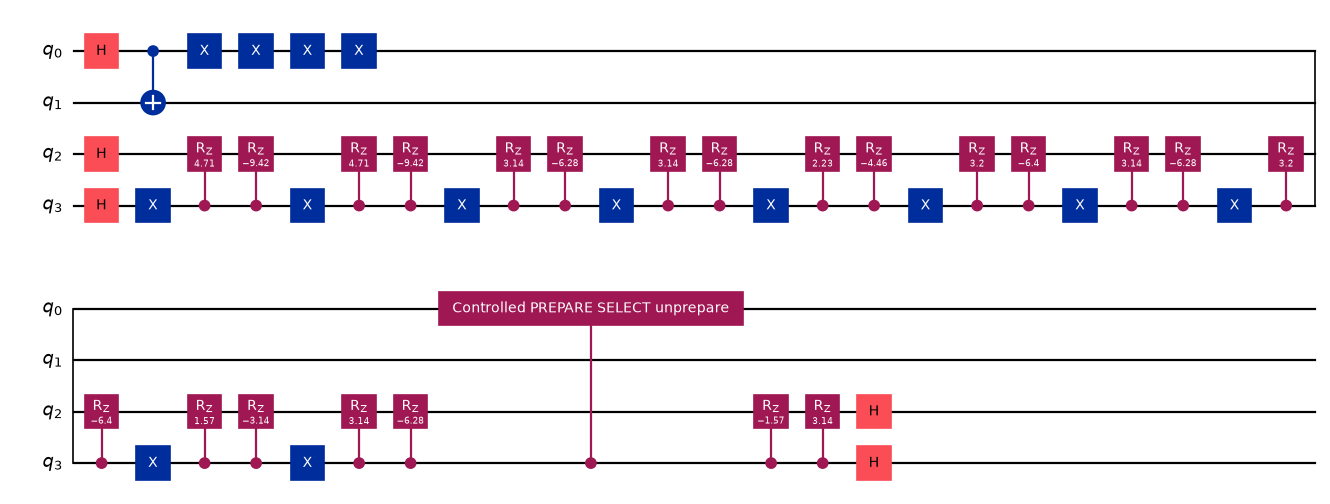

In [2]:
demo=ts.build_thermal_spectral_filter(ts.spin_chain_terms(1),beta=.75)
demo.draw(output="mpl",fold=24,scale=.8)


## Generated parity response

The real sum of $e^{-a}\cosh(ax)/2$ and $-e^{-a}\sinh(ax)/2$, divided by two, targets $e^{-a(x+1)}/4$. A separate analytic/interval coefficient validator accepts the stored phases; the plot is sampled numerical evidence.

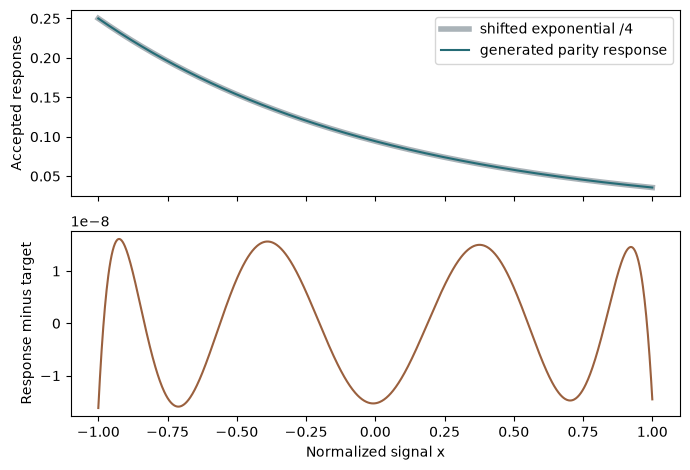

In [3]:
plan=core.metadata["phase_plan"]
a=core.metadata["parameter"]
x=np.linspace(-1,1,1001)
response=(real_qsp_response(x,plan["even_phases"])+real_qsp_response(x,plan["odd_phases"]))/2
reference=np.exp(-a*(x+1))/4
fig,axes=plt.subplots(2,1,figsize=(7,4.8),sharex=True)
axes[0].plot(x,reference,color="#aab3b8",lw=4,label="shifted exponential /4")
axes[0].plot(x,response,color="#246b75",label="generated parity response")
axes[0].set(ylabel="Accepted response");axes[0].legend()
axes[1].plot(x,response-reference,color="#9a603e")
axes[1].set(xlabel="Normalized signal x",ylabel="Response minus target")
axes[1].ticklabel_format(axis="y",style="sci",scilimits=(0,0))
fig.tight_layout();display(fig);plt.close(fig)


## Actual branch and Gibbs check

The system/reference purification is checked before final system readout. Its norm gives acceptance; tracing the reference without conditioning gives the system density. Filter-block, purification and normalized Gibbs errors are distinct. A full filter Operator is checked only within the eight-total-wire cap.

In [4]:
keys=["actual_encoded_filter_operator_error","actual_Bell_branch_vector_error","gibbs_trace_distance","energy_error","actual_acceptance_probability","exact_shifted_filter_acceptance_probability"]
rows=[{"quantity":k,"value":check[k]} for k in keys]
rows.extend({"quantity":k,"value":contract[k]} for k in ["ideal_decoded_total_error_upper","precompiler_source_decoded_total_error_upper","precompiler_source_Gibbs_trace_distance_upper","precompiler_source_acceptance_lower"])
display(pd.DataFrame(rows))


,quantity,value
0,actual_encoded_filter_operator_error,1.591635e-08
1,actual_Bell_branch_vector_error,1.367110e-08
2,gibbs_trace_distance,9.462291e-08
3,energy_error,1.999731e-08
4,actual_acceptance_probability,1.579150e-02
5,exact_shifted_filter_acceptance_probability,1.579150e-02
6,ideal_decoded_total_error_upper,6.475961e-08
7,precompiler_source_decoded_total_error_upper,6.475961e-08
8,precompiler_source_Gibbs_trace_distance_upper,9.103501e-07
9,precompiler_source_acceptance_lower,1.265118e-03


## Temperature grid and size counts

The canonical generator checks nine cases ($n=1,2,3$, $\beta=0,.75,1.5$). Its $n=4$ fixed-$\beta$ row is circuit-only materialization. All rows use fresh phase generation; fixed $\alpha t=4.1$ phases are absent. If canonical files are unavailable, this notebook still executes a smaller one-spin temperature check.

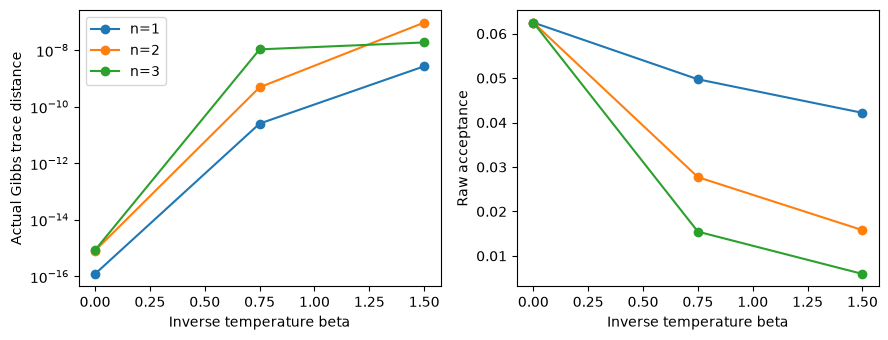

In [5]:
if (asset_dir/"accuracy.csv").exists():
    accuracy=pd.read_csv(asset_dir/"accuracy.csv")
else:
    records=[]
    for beta in (0.,.75,1.5):
        c=ts.build_thermal_spectral_filter(ts.spin_chain_terms(1),beta)
        r=ts.thermal_spectral_check(c)
        records.append({"n_system":1,"beta":beta,"actual_gibbs_trace_distance":r["gibbs_trace_distance"],"actual_acceptance":r["actual_acceptance_probability"]})
    accuracy=pd.DataFrame(records)
fig,axes=plt.subplots(1,2,figsize=(9,3.5))
for size in sorted(accuracy.n_system.unique()):
    group=accuracy[accuracy.n_system==size].sort_values("beta")
    axes[0].semilogy(group.beta,np.maximum(group.actual_gibbs_trace_distance,1e-17),"o-",label=f"n={size}")
    axes[1].plot(group.beta,group.actual_acceptance,"o-",label=f"n={size}")
axes[0].set(xlabel="Inverse temperature beta",ylabel="Actual Gibbs trace distance")
axes[1].set(xlabel="Inverse temperature beta",ylabel="Raw acceptance")
axes[0].legend();fig.tight_layout();display(fig);plt.close(fig)


In [6]:
if (asset_dir/"scaling.csv").exists():
    scaling=pd.read_csv(asset_dir/"scaling.csv")
    display(scaling[["n_system","parameter_a","even_degree","odd_degree","logical_qubits","Z_trial_primitives","Z_trial_depth","state_validation_performed"]])
else:
    records=[]
    for size in (1,2):
        c=ts.build_thermal_spectral_filter(ts.spin_chain_terms(size),beta=1.5)
        z=ts.lower_thermal_spectral(ts.build_thermal_spectral_trial(c,"Z"))
        records.append({"n_system":size,"a":c.metadata["parameter"],"odd_degree":c.metadata["odd_degree"],"logical_qubits":c.num_qubits,"Z_trial_primitives":z.size()})
    display(pd.DataFrame(records))


,n_system,parameter_a,even_degree,odd_degree,logical_qubits,Z_trial_primitives,Z_trial_depth,state_validation_performed
0,1,0.2625,4,5,4,112,92,True
1,2,0.9750,6,7,8,1672,1185,True
2,3,1.6875,8,9,11,5868,4239,True
3,4,2.4000,10,11,13,8958,6551,False


## Complete measured energy workload

Each X/Z trial starts with actual resets, prepares Bell pairs, runs the complete coherent filter, measures every success bit, resets the reference without conditioning, rotates the system basis and reads the system. Every rejected attempt pays the entire circuit. The source certificate does not cover reset/readout faults. Grouped accepted-shot/retry budgets are unexecuted proposals; no hardware samples are reported.

In [7]:
trials={axis:ts.lower_thermal_spectral(ts.build_thermal_spectral_trial(core,axis)) for axis in ("X","Z")}
workload=ts.energy_workload(check["actual_acceptance_probability"],2,.6,.35)
rows=[]
for axis,trial in trials.items():
    counts=dict(trial.count_ops())
    group=workload["groups"][axis]
    rows.append({"group":axis,"operations_per_attempt":trial.size(),"depth":trial.depth(),"resets":counts.get("reset",0),"measurements":counts.get("measure",0),"accepted_trials":group["accepted_trials"],"retry_cap":workload["retry_cap_per_slot"],"complete_attempt_cap":group["accepted_trials"]*workload["retry_cap_per_slot"]})
    assert counts["reset"]==core.num_qubits+2
    assert counts["measure"]==core.num_qubits-2
print("Unexecuted capped workload:",workload["complete_attempt_cap"],"complete attempts")
display(pd.DataFrame(rows))


Unexecuted capped workload: 51214098 complete attempts


,group,operations_per_attempt,depth,resets,measurements,accepted_trials,retry_cap,complete_attempt_cap
0,X,1672,1185,10,6,29116,1014,29523624
1,Z,1672,1185,10,6,21391,1014,21690474


## Reproducibility and boundaries

Run `python generate_simulation_thermal_spectral.py` with all copied modules and `LICENSE.txt` for a standalone package. `--no-sim` still fits/validates phases and materializes circuits; actual state/reference/readout checks are unperformed. No widget objects are created in a static build.

Source maxima and simulator caps are separate. The chapter records continuum coefficient and logical PREPARE-weight bounds, exact input normalization/parameter rounding, numerical source/primitive comparisons, and unavailable compiler/synthesis/instrument/physical certificates. No equal-task quantum advantage or formal/Lean proof is claimed.